### Exercise 4 - Does a Second Hidden Layer Help?

A - Train the Deeper Network

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split

# Initialize once, matching your standalone Exercise 3 notebook.
rng = np.random.default_rng(42)

X, y = make_classification(
    n_samples=1500,
    n_features=4,
    n_informative=4,
    n_redundant=0,
    n_repeated=0,
    n_classes=3,
    n_clusters_per_class=2,
    class_sep=1.0,
    random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [5]:
class MLP:
    """Configurable MLP with tanh hidden layers."""

    def __init__(self, layer_sizes, rng, task="binary"):
        if task not in ("binary", "multiclass"):
            raise ValueError("task must be 'binary' or 'multiclass'.")

        if len(layer_sizes) < 3 or any(s < 1 for s in layer_sizes):
            raise ValueError("Use positive sizes and at least one hidden layer.")

        if task == "binary" and layer_sizes[-1] != 1:
            raise ValueError("Binary classification requires one output.")

        if task == "multiclass" and layer_sizes[-1] < 2:
            raise ValueError("Multiclass classification requires multiple outputs.")

        self.task = task
        self.n_outputs = layer_sizes[-1]
        self.weights = []
        self.biases = []

        for n_in, n_out in zip(layer_sizes[:-1], layer_sizes[1:]):
            limit = np.sqrt(6.0 / (n_in + n_out))
            self.weights.append(
                rng.uniform(-limit, limit, size=(n_in, n_out))
            )
            self.biases.append(np.zeros((1, n_out)))

    def output_activation(self, logits):
        if self.task == "binary":
            return np.exp(-np.logaddexp(0.0, -logits))

        shifted = logits - np.max(logits, axis=1, keepdims=True)
        exp_values = np.exp(shifted)
        return exp_values / np.sum(exp_values, axis=1, keepdims=True)

    def encode_targets(self, y):
        if self.task == "binary":
            return np.asarray(y).reshape(-1, 1)

        # Integer labels 0, ..., K-1 become one-hot rows.
        labels = np.asarray(y, dtype=int).ravel()
        return np.eye(self.n_outputs)[labels]

    def forward(self, X):
        activations = [X]

        for W, b in zip(self.weights[:-1], self.biases[:-1]):
            z = activations[-1] @ W + b
            activations.append(np.tanh(z))

        logits = (
            activations[-1] @ self.weights[-1] + self.biases[-1]
        )
        activations.append(self.output_activation(logits))

        return activations, logits

    def loss(self, logits, y):
        targets = self.encode_targets(y)

        if self.task == "binary":
            return float(np.mean(
                np.logaddexp(0.0, logits) - targets * logits
            ))

        # Stable log-softmax, without taking log of rounded probabilities.
        shifted = logits - np.max(logits, axis=1, keepdims=True)
        log_probs = shifted - np.log(
            np.sum(np.exp(shifted), axis=1, keepdims=True)
        )

        return float(-np.mean(np.sum(targets * log_probs, axis=1)))

    def backward(self, activations, y):
        targets = self.encode_targets(y)
        m = targets.shape[0]

        # Valid for both supported activation–loss pairs.
        delta = (activations[-1] - targets) / m

        dW = [None] * len(self.weights)
        db = [None] * len(self.biases)

        for layer in range(len(self.weights) - 1, -1, -1):
            dW[layer] = activations[layer].T @ delta
            db[layer] = np.sum(delta, axis=0, keepdims=True)

            if layer > 0:
                delta = (
                    delta @ self.weights[layer].T
                ) * (1 - activations[layer] ** 2)

        return dW, db

    def update(self, dW, db, learning_rate):
        for layer in range(len(self.weights)):
            self.weights[layer] -= learning_rate * dW[layer]
            self.biases[layer] -= learning_rate * db[layer]

    def fit(self, X, y, learning_rate=0.1, epochs=2000):
        history = []

        for _ in range(epochs):
            activations, _ = self.forward(X)
            dW, db = self.backward(activations, y)
            self.update(dW, db, learning_rate)

            _, logits = self.forward(X)
            history.append(self.loss(logits, y))

        return np.array(history)

    def predict_proba(self, X):
        activations, _ = self.forward(X)
        probabilities = activations[-1]

        if self.task == "binary":
            return probabilities.ravel()

        return probabilities

    def predict(self, X):
        probabilities = self.predict_proba(X)

        if self.task == "binary":
            return (probabilities >= 0.5).astype(int)

        return np.argmax(probabilities, axis=1)

In [6]:
model_deeper = MLP([4, 8, 8, 3], rng, task="multiclass")

learning_rate = 0.1
epochs = 2000

training_loss_deeper = model_deeper.fit(
    X_train,
    y_train,
    learning_rate=learning_rate,
    epochs=epochs
)

y_pred_deeper = model_deeper.predict(X_test)
deeper_accuracy = np.mean(y_pred_deeper == y_test)

print("Architecture: [4, 8, 8, 3]")
print(f"Learning rate: {learning_rate}")
print(f"Epochs: {epochs}")
print(f"Test accuracy: {deeper_accuracy:.2%}")
print(f"Final training loss: {training_loss_deeper[-1]:.6f}")

Architecture: [4, 8, 8, 3]
Learning rate: 0.1
Epochs: 2000
Test accuracy: 85.67%
Final training loss: 0.322877


The deeper MLP uses the architecture 4 → 8 → 8 → 3, with two hidden layers of eight tanh neurons each. After 2,000 epochs of full-batch gradient descent at learning rate 0.1, its test accuracy is 85.67%, corresponding to 257 correct predictions out of 300. The final training categorical cross-entropy is 0.322877.

| Setting | Exercise 3 | Exercise 4 |
|---|---:|---:|
| Architecture | 4 → 8 → 3 | 4 → 8 → 8 → 3 |
| Learning rate | 0.1 | 0.1 |
| Epochs | 2,000 | 2,000 |
| Test accuracy | 84.67% | 85.67% |
| Correct predictions | 254/300 | 257/300 |
| Final training loss | 0.395544 | 0.322877 |

In this fixed-seed comparison, the added layer improves test accuracy by 1.00 percentage point, or three additional correct predictions. This is a modest gain in this run, rather than evidence that adding depth always improves generalization. The epoch budget is held fixed; the deeper model has more parameters and requires more computation per epoch.

B - Compare

In [7]:
seeds = [42, 43, 44]
architectures = {
    "Exercise 3": [4, 8, 3],
    "Exercise 4": [4, 8, 8, 3]
}
learning_rate = 0.1
epochs = 2000

results = []
histories = {name: [] for name in architectures}

for seed in seeds:
    # The explicit multi-seed experiment uses one generator per seed.
    rng = np.random.default_rng(seed)
    initial_state = rng.bit_generator.state

    for name, sizes in architectures.items():
        # Give each architecture the same starting RNG state for this seed.
        rng.bit_generator.state = initial_state
        network = MLP(sizes, rng, task="multiclass")

        losses = network.fit(
            X_train, y_train,
            learning_rate=learning_rate,
            epochs=epochs
        )
        predictions = network.predict(X_test)
        accuracy = np.mean(predictions == y_test)
        parameters = sum(
            W.size + b.size
            for W, b in zip(network.weights, network.biases)
        )

        histories[name].append(losses)
        results.append({
            "seed": seed,
            "model": name,
            "parameters": parameters,
            "final_train_loss": float(losses[-1]),
            "test_accuracy": float(accuracy)
        })
        print(f"Seed {seed} | {name} | parameters={parameters} | "
              f"loss={losses[-1]:.6f} | accuracy={accuracy:.2%}")

for name in architectures:
    rows = [row for row in results if row["model"] == name]
    final_losses = np.array([row["final_train_loss"] for row in rows])
    accuracies = np.array([row["test_accuracy"] for row in rows])
    print(f"{name}: mean final loss={final_losses.mean():.6f} "
          f"(sample SD={final_losses.std(ddof=1):.6f}); "
          f"mean accuracy={accuracies.mean():.2%} "
          f"(sample SD={100 * accuracies.std(ddof=1):.2f} percentage points)")


Seed 42 | Exercise 3 | parameters=67 | loss=0.395544 | accuracy=84.67%
Seed 42 | Exercise 4 | parameters=139 | loss=0.322877 | accuracy=85.67%
Seed 43 | Exercise 3 | parameters=67 | loss=0.406294 | accuracy=82.33%
Seed 43 | Exercise 4 | parameters=139 | loss=0.322618 | accuracy=83.67%
Seed 44 | Exercise 3 | parameters=67 | loss=0.350463 | accuracy=83.67%
Seed 44 | Exercise 4 | parameters=139 | loss=0.335267 | accuracy=83.33%
Exercise 3: mean final loss=0.384100 (sample SD=0.029622); mean accuracy=83.56% (sample SD=1.17 percentage points)
Exercise 4: mean final loss=0.326921 (sample SD=0.007229); mean accuracy=84.22% (sample SD=1.26 percentage points)


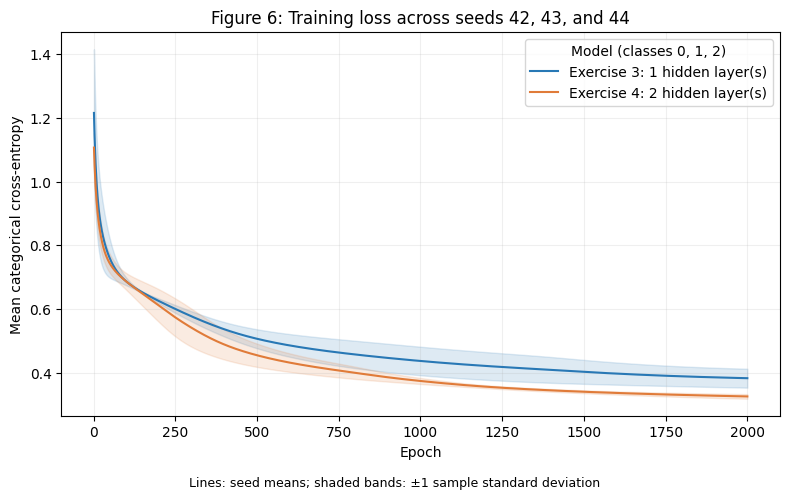

In [9]:
fig, ax = plt.subplots(figsize=(8, 5))
epoch_numbers = np.arange(1, epochs + 1)

for name, color in [("Exercise 3", "#2878b5"), ("Exercise 4", "#e07b39")]:
    curves = np.asarray(histories[name])
    mean_loss = curves.mean(axis=0)
    std_loss = curves.std(axis=0, ddof=1)
    hidden_layers = len(architectures[name]) - 2

    ax.plot(
        epoch_numbers, mean_loss, color=color,
        label=f"{name}: {hidden_layers} hidden layer(s)"
    )
    ax.fill_between(
        epoch_numbers, mean_loss - std_loss, mean_loss + std_loss,
        color=color, alpha=0.15
    )

ax.set_title("Figure 6: Training loss across seeds 42, 43, and 44")
ax.set_xlabel("Epoch")
ax.set_ylabel("Mean categorical cross-entropy")
ax.legend(title="Model (classes 0, 1, 2)")
ax.grid(alpha=0.2)
fig.text(0.5, 0.015, "Lines: seed means; shaded bands: ±1 sample standard deviation",
         ha="center", fontsize=9)
fig.tight_layout(rect=[0, 0.04, 1, 1])
fig.savefig("./figures/figure6.png", dpi=180)
plt.show()


| Model | Hidden layers | Parameters | Mean final train loss | Mean test accuracy |
|---|---:|---:|---:|---:|
| Exercise 3: 4 → 8 → 3 | 1 | **67** | **0.384100** | **83.56%** |
| Exercise 4: 4 → 8 → 8 → 3 | 2 | **139** | **0.326921** | **84.22%** |

- Exercise 3: $(4\times8+8)+(8\times3+3)=\mathbf{67}$.
- Exercise 4: $(4\times8+8)+(8\times8+8)+(8\times3+3)=\mathbf{139}$.

| Seed | Exercise 3 final loss | Exercise 3 test accuracy | Exercise 4 final loss | Exercise 4 test accuracy |
|---|---:|---:|---:|---:|
| 42 | 0.395544 | 84.67% | 0.322877 | 85.67% |
| 43 | 0.406294 | 82.33% | 0.322618 | 83.67% |
| 44 | 0.350463 | 83.67% | 0.335267 | 83.33% |

The sample standard deviations across seeds are 0.029622 and 0.007229 for final training loss, and 1.17 and 1.26 percentage points for test accuracy, for Exercises 3 and 4 respectively. The shaded bands in Figure 6 show one sample standard deviation across seeds, not confidence intervals.

The deeper network reduces training loss in all three runs and improves mean test accuracy by 0.67 percentage points. It performs better on seeds 42 and 43, but slightly worse on seed 44. This suggests a modest average benefit in this experiment, rather than a consistent improvement for every initialization. Three seeds on one split provide limited evidence about broader generalization.

C - Analysis

Across seeds 42, 43, and 44, the deeper network achieved 84.22% mean test accuracy, compared with 83.56% for the shallower network—a modest improvement of 0.67 percentage points. It performed better on two seeds and slightly worse on the third. These measurements suggest a small benefit in this experiment, rather than a reliable advantage from additional depth.

The dataset contains six clusters in four informative dimensions, with two clusters per class. Although separating these classes requires nonlinear boundaries, a single hidden layer with eight `tanh` neurons can already represent much of this structure. Six clusters do not necessarily require a deep hierarchy of features.

A second hidden layer adds another nonlinear transformation, allowing the network to compose features and represent more complex boundaries. However, it also increases the parameter count from 67 to 139 and introduces additional stages through which gradients must propagate. This can make optimization more sensitive to initialization and increase computation per epoch.

The training loss shows a clearer improvement than test accuracy: mean final loss decreased from 0.384100 to 0.326921, and the deeper model had lower training loss for every seed. However, this did not consistently produce better test predictions. Cross-entropy also reflects prediction confidence, whereas accuracy measures only whether the highest-probability class is correct. Lower training loss therefore does not guarantee higher test accuracy, and these results alone do not establish overfitting.

Extra depth would be more likely to help on data with hierarchical or compositional structure, where successive layers can build useful representations—for example, image recognition, where simple visual patterns combine into shapes and objects. Sufficient training data and effective optimization would also be needed to turn that additional representational capacity into better generalization.